Project 3 - Giovanni Miquelin, João Lucas Guerra,
# HOW TO WIN A F1 RACE - DATA


**# CLASSIC ERA**

In [ ]:
# SCRIPT FOR PROJECT DATA ANALYSIS 3 - F1 DATA - GBM
# Used Gemini for comment generation
# All graphs used and made for classic ERA
library(dplyr)
library(ggplot2)


getwd()
f1_data = read.csv("f1_master_data.csv")
View(f1_data)




[1] "/content"

resultId,raceId,driverId,constructorId,car_number,grid,finish_position,finish_position_text,finish_position_order,race_points,⋯,avg_lap_ms,median_lap_ms,min_lap_ms,max_lap_ms,sd_lap_ms,total_pit_stops,total_pit_ms,avg_pit_ms,min_pit_ms,max_pit_ms
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,18,1,1,22,1,1,1,1,10.0,⋯,98114.07,88665.5,87452,166432,20990.36,NA,NA,NA,NA,NA
2,18,2,2,3,5,2,2,2,8.0,⋯,98208.52,89388.0,87739,166678,20212.30,NA,NA,NA,NA,NA
3,18,3,3,7,7,3,3,3,6.0,⋯,98254.81,89585.0,88090,156683,18957.20,NA,NA,NA,NA,NA
4,18,4,4,5,11,4,4,4,5.0,⋯,98410.29,90668.5,88603,170306,19640.82,NA,NA,NA,NA,NA
5,18,5,1,23,3,5,5,5,4.0,⋯,98424.66,89442.5,87418,175160,21826.40,NA,NA,NA,NA,NA
6,18,6,3,8,13,6,6,6,3.0,⋯,100082.19,91704.0,89639,209104,22953.24,NA,NA,NA,NA,NA
7,18,7,5,14,17,7,7,7,2.0,⋯,98864.38,91329.0,89534,156156,17491.81,NA,NA,NA,NA,NA
8,18,8,6,1,15,8,8,8,1.0,⋯,99534.72,90511.0,87903,160433,19536.83,NA,NA,NA,NA,NA
9,18,9,2,4,2,NA,R,9,0.0,⋯,99290.74,90473.0,88753,174039,20625.53,NA,NA,NA,NA,NA


In [ ]:
# Filter for 1950-1980 and group race statuses into simple categories
classic_era_summary = f1_data %>%
  filter(year >= 1950 & year <= 1980) %>%
  mutate(
    Finish_Outcome = case_when(
      race_status == "Finished" ~ "Finished on the Lead Lap",
      race_status %in% c("+1 Lap", "+2 Laps", "+3 Laps") ~ "Finished 1 to 3 Laps Down",
      grepl("Laps", race_status) ~ "Finished 4+ Laps Down", # Catches remaining "+X Laps"
      race_status %in% c("Did not qualify", "Excluded", "Not pre-qualified") ~ "Failed to Qualify (DNQ) / Excluded",
      TRUE ~ "Other (Mechanical DNF, Crash, etc.)"
    )
  ) %>%
  # Count each outcome, calculate percentage, and sort from highest to lowest
  group_by(Finish_Outcome) %>%
  summarise(Count = n()) %>%
  mutate(Percentage = paste0(round((Count / sum(Count)) * 100, 1), "%")) %>%
  arrange(desc(Count))

# Display the summary table
print(classic_era_summary)

# A tibble: 5 × 3
  Finish_Outcome                      Count Percentage
  <chr>                               <int> <chr>     
1 Other (Mechanical DNF, Crash, etc.)  3958 47.6%     
2 Finished 1 to 3 Laps Down            1583 19%       
3 Finished on the Lead Lap             1557 18.7%     
4 Finished 4+ Laps Down                 747 9%        
5 Failed to Qualify (DNQ) / Excluded    468 5.6%      


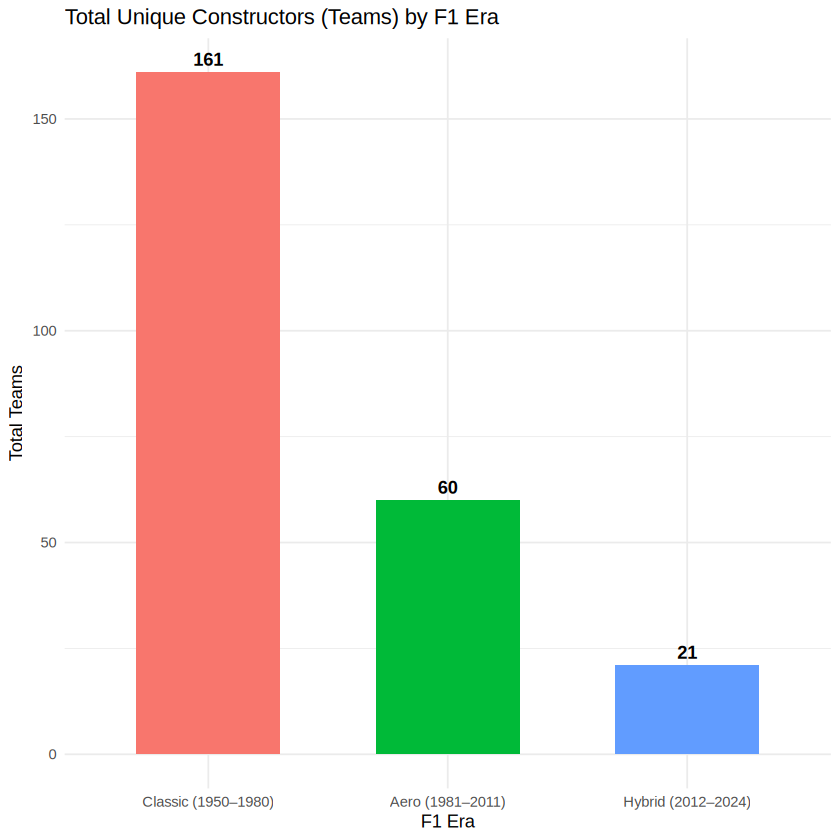

In [ ]:
# Create data frame with ordered Era categories
f1_teams_data = data.frame(
  Era = factor(c("Classic (1950–1980)", "Aero (1981–2011)", "Hybrid (2012–2024)"),
               levels = c("Classic (1950–1980)", "Aero (1981–2011)", "Hybrid (2012–2024)")),
  Total_Teams = c(161, 60, 21)
)

# Plot bar chart with values labeled above each bar
teams_plot = ggplot(f1_teams_data, aes(x = Era, y = Total_Teams, fill = Era)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = Total_Teams), vjust = -0.5, fontface = "bold") +
  theme_minimal() +
  theme(legend.position = "none") +
  labs(
    title = "Total Unique Constructors (Teams) by F1 Era",
    x = "F1 Era",
    y = "Total Teams"
  )

print(teams_plot)

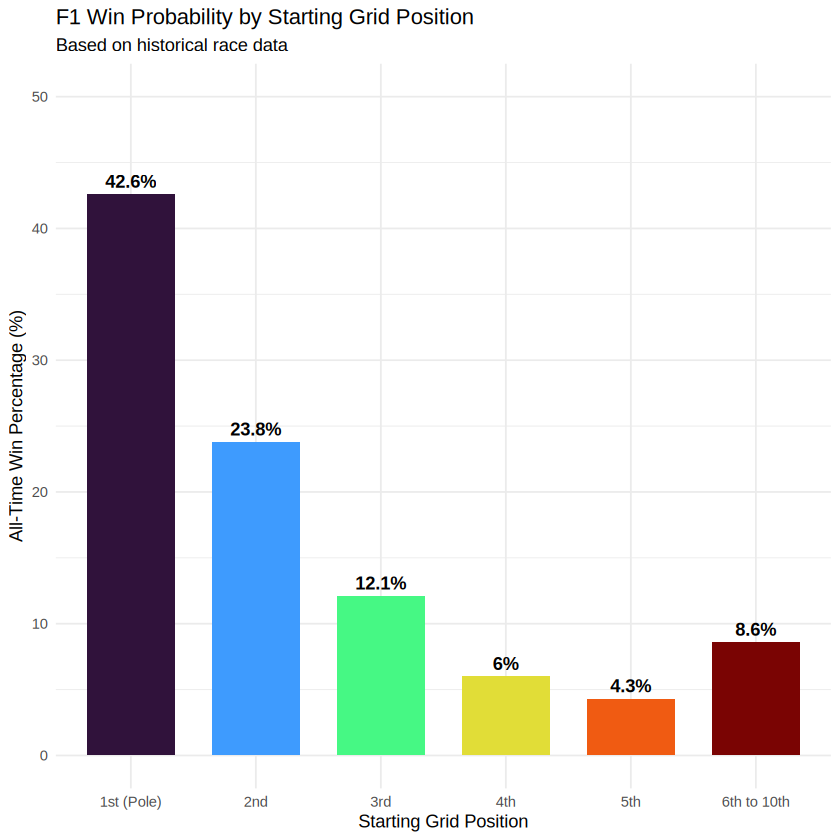

In [ ]:
# Create data frame for all-time grid win percentages
grid_data = data.frame(
  Grid_Position = factor(c("1st (Pole)", "2nd", "3rd", "4th", "5th", "6th to 10th"),
                         levels = c("1st (Pole)", "2nd", "3rd", "4th", "5th", "6th to 10th")),
  Total_Wins = c(481, 268, 137, 68, 49, 97),
  Win_Percentage = c(42.6, 23.8, 12.1, 6.0, 4.3, 8.6)
)

# Plot bar chart with percentage labels and extended y-axis headroom
grid_plot = ggplot(grid_data, aes(x = Grid_Position, y = Win_Percentage, fill = Grid_Position)) +
  geom_col(width = 0.7) +
  geom_text(aes(label = paste0(Win_Percentage, "%")), vjust = -0.5, fontface = "bold") +
  scale_fill_viridis_d(option = "turbo") +
  ylim(0, 50) +
  theme_minimal() +
  theme(legend.position = "none") +
  labs(
    title = "F1 Win Probability by Starting Grid Position",
    subtitle = "Based on historical race data",
    x = "Starting Grid Position",
    y = "All-Time Win Percentage (%)"
  )

print(grid_plot)

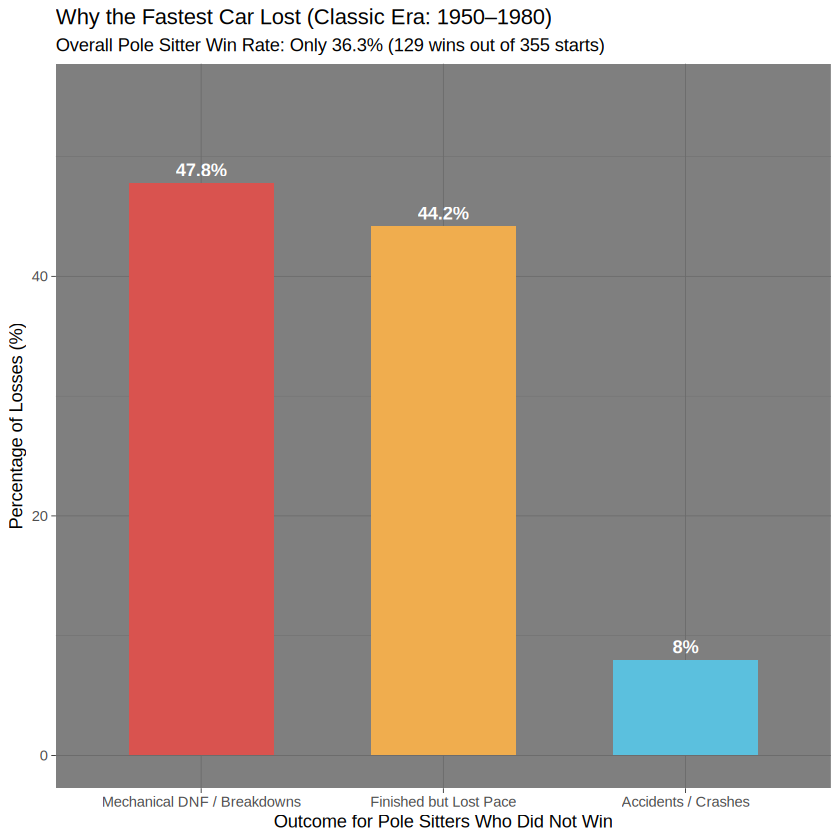

In [ ]:
# Create data frame for pole sitter losses
pole_loss_data = data.frame(
  Outcome = factor(c("Mechanical DNF / Breakdowns", "Finished but Lost Pace", "Accidents / Crashes"),
                   levels = c("Mechanical DNF / Breakdowns", "Finished but Lost Pace", "Accidents / Crashes")),
  Percentage = c(47.8, 44.2, 8.0)
)

# Plot dark-themed bar chart with custom bar colors
loss_plot = ggplot(pole_loss_data, aes(x = Outcome, y = Percentage, fill = Outcome)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = paste0(Percentage, "%")), vjust = -0.5, color = "white", fontface = "bold") +
  scale_fill_manual(values = c("#d9534f", "#f0ad4e", "#5bc0de")) +
  ylim(0, 55) +
  theme_dark() +
  theme(legend.position = "none") +
  labs(
    title = "Why the Fastest Car Lost (Classic Era: 1950–1980)",
    subtitle = "Overall Pole Sitter Win Rate: Only 36.3% (129 wins out of 355 starts)",
    x = "Outcome for Pole Sitters Who Did Not Win",
    y = "Percentage of Losses (%)"
  )

print(loss_plot)

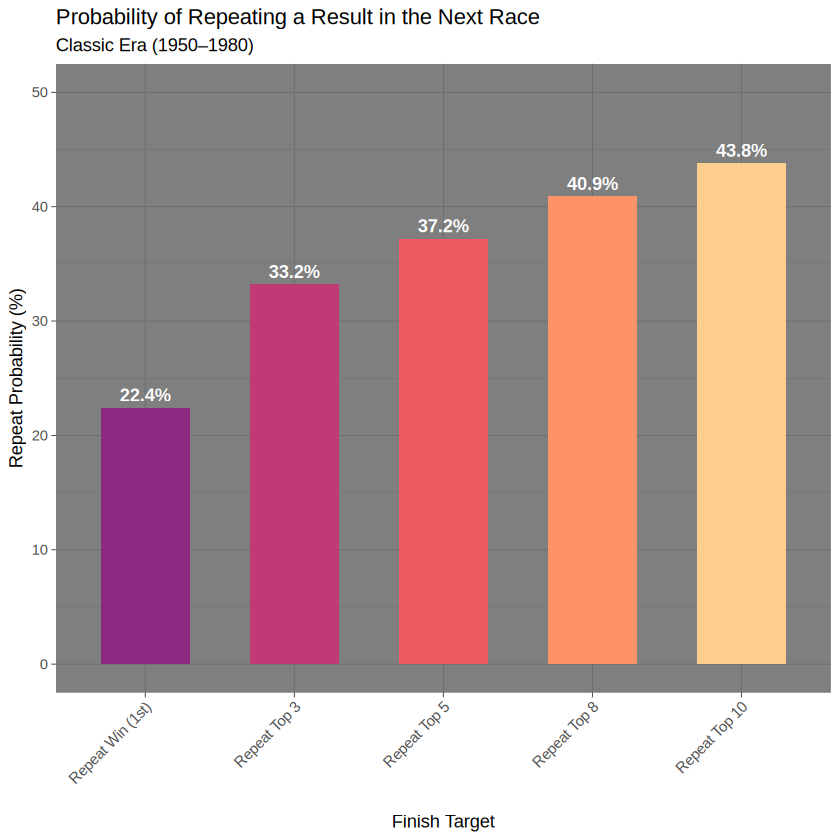

In [ ]:
# Create data frame for repeat finish probabilities
repeat_data = data.frame(
  Finish_Group = factor(c("Repeat Win (1st)", "Repeat Top 3", "Repeat Top 5", "Repeat Top 8", "Repeat Top 10"),
                        levels = c("Repeat Win (1st)", "Repeat Top 3", "Repeat Top 5", "Repeat Top 8", "Repeat Top 10")),
  Probability = c(22.4, 33.2, 37.2, 40.9, 43.8)
)

# Plot dark-themed bar chart with angled x-axis labels
repeat_plot = ggplot(repeat_data, aes(x = Finish_Group, y = Probability, fill = Finish_Group)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = paste0(Probability, "%")), vjust = -0.5, color = "white", fontface = "bold") +
  scale_fill_viridis_d(option = "magma", begin = 0.4, end = 0.9) +
  ylim(0, 50) +
  theme_dark() +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1) # Tilts labels so they don't overlap
  ) +
  labs(
    title = "Probability of Repeating a Result in the Next Race",
    subtitle = "Classic Era (1950–1980)",
    x = "Finish Target",
    y = "Repeat Probability (%)"
  )

print(repeat_plot)

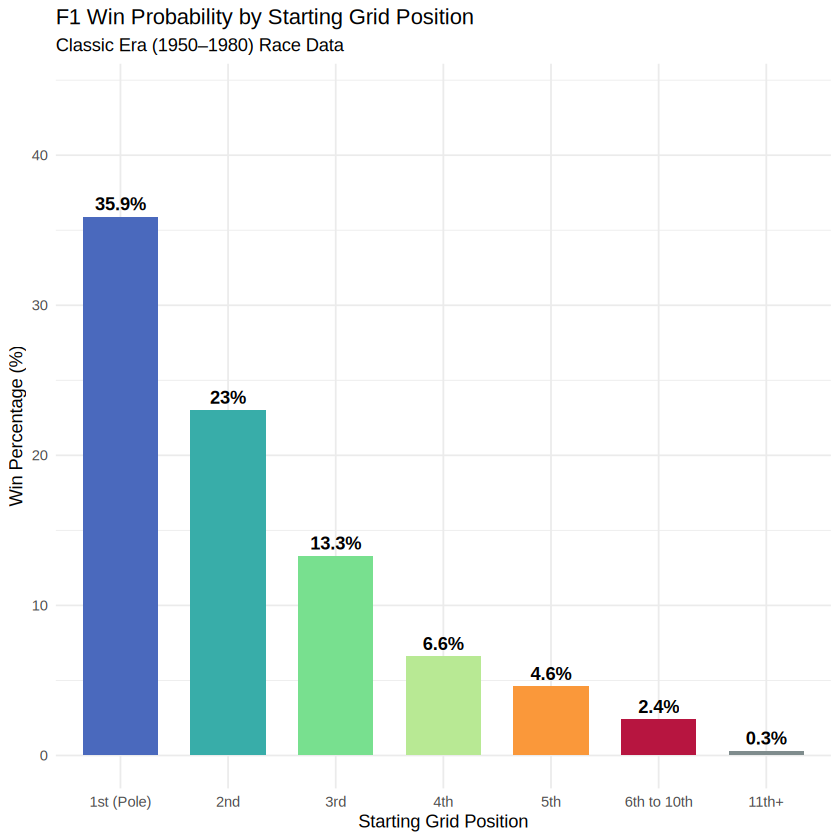

In [ ]:
# Filter Classic Era valid grid starts, group positions, and calculate win %
classic_grid_stats = f1_data %>%
  filter(year >= 1950 & year <= 1980) %>%
  mutate(
    grid = as.numeric(grid),
    finish_position_order = as.numeric(finish_position_order)
  ) %>%
  filter(grid > 0) %>% # Excludes pit lane starts (grid = 0)
  mutate(
    Grid_Group = case_when(
      grid == 1 ~ "1st (Pole)",
      grid == 2 ~ "2nd",
      grid == 3 ~ "3rd",
      grid == 4 ~ "4th",
      grid == 5 ~ "5th",
      grid >= 6 & grid <= 10 ~ "6th to 10th",
      grid > 10 ~ "11th+"
    ),
    Grid_Group = factor(Grid_Group, levels = c("1st (Pole)", "2nd", "3rd", "4th", "5th", "6th to 10th", "11th+"))
  ) %>%
  group_by(Grid_Group) %>%
  summarise(
    Total_Starts = n(),
    Total_Wins = sum(finish_position_order == 1, na.rm = TRUE),
    Win_Percentage = round((Total_Wins / Total_Starts) * 100, 1)
  )

# Plot bar chart with custom colors matching each grid group
classic_grid_plot = ggplot(classic_grid_stats, aes(x = Grid_Group, y = Win_Percentage, fill = Grid_Group)) +
  geom_col(width = 0.7) +
  geom_text(aes(label = paste0(Win_Percentage, "%")), vjust = -0.5, fontface = "bold") +
  scale_fill_manual(values = c("#4a69bd", "#38ada9", "#78e08f", "#b8e994", "#fa983a", "#b71540", "#7f8c8d")) +
  ylim(0, max(classic_grid_stats$Win_Percentage) + 8) +
  theme_minimal() +
  theme(legend.position = "none") +
  labs(
    title = "F1 Win Probability by Starting Grid Position",
    subtitle = "Classic Era (1950–1980) Race Data",
    x = "Starting Grid Position",
    y = "Win Percentage (%)"
  )

print(classic_grid_plot)

**#AERODYANAMIC ERA**

**#HYBRID ERA**

In [ ]:
# DATA ANALYSIS PROJECT 3 - F1 DATA - JLG
# Used Gemini for comment, generation and debugging.

# Load necessary libraries
library(dplyr)
library(ggplot2)

# Load the master dataset
df = read.csv("f1_master_dataset.csv")

# Filter the data for the Hybrid Era (2014 - 2024)
df_hybrid = df %>%
  filter(year >= 2014)

# Display the first few rows to check if everything is correct
head(df_hybrid)

,resultId,raceId,driverId,constructorId,car_number,grid,finish_position,finish_position_text,finish_position_order,race_points,⋯,avg_lap_ms,median_lap_ms,min_lap_ms,max_lap_ms,sd_lap_ms,total_pit_stops,total_pit_ms,avg_pit_ms,min_pit_ms,max_pit_ms
,<int>,<int>,<int>,<int>,<dbl>,<int>,<dbl>,<chr>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,22130,900,3,131,6,3,1,1,1,25,⋯,97872.11,94040,92478,149953,12238.52,2,48004,24002.0,23673,24331
2,22131,900,825,1,20,4,2,2,2,18,⋯,98341.88,94995,92917,140764,11084.17,2,45423,22711.5,22273,23150
3,22132,900,18,1,22,10,3,3,3,15,⋯,98398.89,95341,93186,140580,9857.22,2,44810,22405.0,22399,22411
4,22133,900,4,6,14,5,4,4,4,12,⋯,98491.12,95374,92616,140389,10747.01,2,44865,22432.5,21978,22887
5,22134,900,822,3,77,15,5,5,5,10,⋯,98707.88,95211,92568,156286,10793.19,2,58038,29019.0,23117,34921
6,22135,900,807,10,27,7,6,6,6,8,⋯,98761.89,95457,93210,141039,10714.07,2,45548,22774.0,22615,22933


In [ ]:
# 1. Calculate General Characteristics
hybrid_characteristics = df_hybrid %>%
  summarise(
    Total_Races = n_distinct(raceId),
    Unique_Drivers = n_distinct(driverId),
    Unique_Teams = n_distinct(constructorId)
  )

cat("--- HYBRID ERA CHARACTERISTICS (2014-2024) ---\n")
print(hybrid_characteristics)
cat("\n")

# 2. Top 10 Drivers by Wins
# finish_position_order == 1 means the driver won the race
top_drivers_hybrid = df_hybrid %>%
  filter(finish_position_order == 1) %>%
  group_by(driver_surname) %>%
  summarise(Total_Wins = n()) %>%
  arrange(desc(Total_Wins)) %>%
  slice_head(n = 10)

cat("--- TOP 10 DRIVERS (Wins) ---\n")
print(top_drivers_hybrid)
cat("\n")

# 3. Top 10 Constructors by Wins
top_teams_hybrid = df_hybrid %>%
  filter(finish_position_order == 1) %>%
  group_by(constructor_name) %>%
  summarise(Total_Wins = n()) %>%
  arrange(desc(Total_Wins)) %>%
  slice_head(n = 10)

cat("--- TOP 10 TEAMS (Wins) ---\n")
print(top_teams_hybrid)

--- HYBRID ERA CHARACTERISTICS (2014-2024) ---
  Total_Races Unique_Drivers Unique_Teams
1         228             59           20

--- TOP 10 DRIVERS (Wins) ---
# A tibble: 10 × 2
   driver_surname Total_Wins
   <chr>               <int>
 1 Hamilton               83
 2 Verstappen             63
 3 Rosberg                20
 4 Vettel                 14
 5 Bottas                 10
 6 Leclerc                 8
 7 Ricciardo               8
 8 Pérez                   6
 9 Norris                  4
10 Sainz                   4

--- TOP 10 TEAMS (Wins) ---
# A tibble: 7 × 2
  constructor_name Total_Wins
  <chr>                 <int>
1 Mercedes                116
2 Red Bull                 75
3 Ferrari                  27
4 McLaren                   7
5 AlphaTauri                1
6 Alpine F1 Team            1
7 Racing Point              1


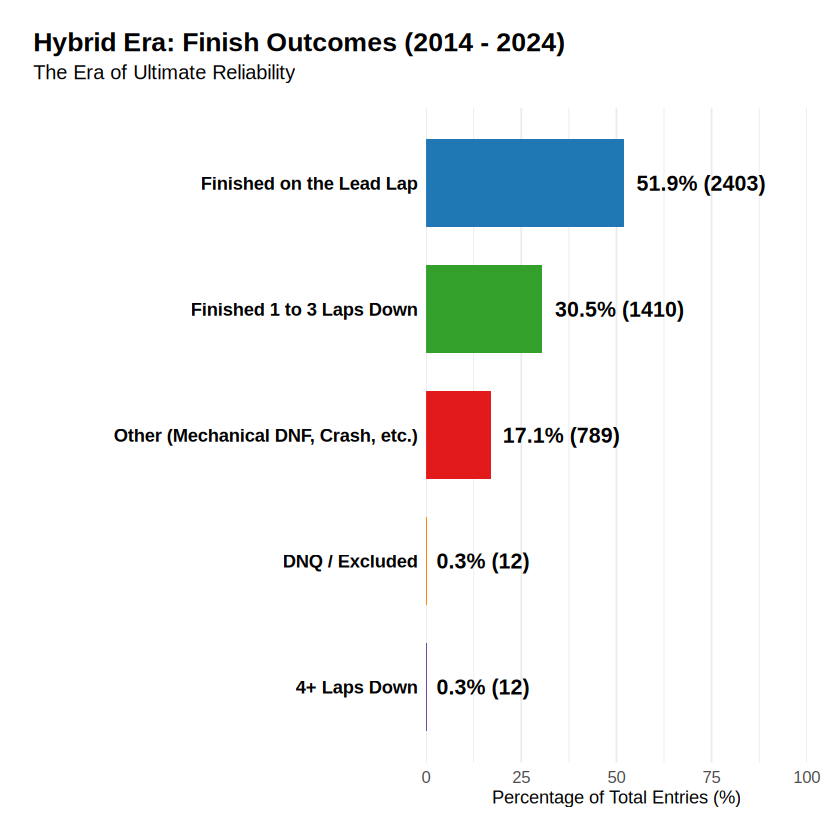

In [ ]:
# 1. Categorize the race finish status based on statusId
df_outcomes = df_hybrid %>%
  mutate(
    Outcome_Category = case_when(
      statusId == 1 ~ "Finished on the Lead Lap",
      statusId %in% c(11, 12, 13) ~ "Finished 1 to 3 Laps Down",
      statusId %in% c(2, 62, 96) ~ "DNQ / Excluded",
      grepl("\\+", race_status) & !statusId %in% c(11, 12, 13) ~ "4+ Laps Down",
      TRUE ~ "Other (Mechanical DNF, Crash, etc.)"
    )
  ) %>%
  group_by(Outcome_Category) %>%
  summarise(Count = n(), .groups = "drop") %>%
  mutate(
    Percentage = round((Count / sum(Count)) * 100, 1),
    # Reorder the categories by Count to keep the stair effect
    Outcome_Category = reorder(Outcome_Category, Count)
  )

# 2. Create a Horizontal Bar Chart using ggplot2
ggplot(df_outcomes, aes(x = Percentage, y = Outcome_Category, fill = Outcome_Category)) +
  geom_bar(stat = "identity", width = 0.7, show.legend = FALSE) +
  geom_text(aes(label = paste0(Percentage, "% (", Count, ")")),
            hjust = -0.1, size = 4.5, fontface = "bold", color = "black") +
  scale_x_continuous(limits = c(0, 100), expand = c(0, 0)) +
  scale_fill_manual(
    values = c(
      "Other (Mechanical DNF, Crash, etc.)" = "#e31a1c",
      "Finished on the Lead Lap" = "#1f78b4",
      "Finished 1 to 3 Laps Down" = "#33a02c",
      "DNQ / Excluded" = "#ff7f00",
      "4+ Laps Down" = "#6a3d9a"
    )
  ) +
  theme_minimal() +
  labs(
    title = "Hybrid Era: Finish Outcomes (2014 - 2024)",
    subtitle = "The Era of Ultimate Reliability",
    x = "Percentage of Total Entries (%)",
    y = NULL
  ) +
  theme(
    plot.title.position = "plot", # Force the alignment of the whole chart to the left
    plot.title = element_text(face = "bold", size = 16),
    plot.subtitle = element_text(size = 12, margin = margin(b = 15)),
    axis.text.y = element_text(size = 11, face = "bold", color = "black"),
    axis.text.x = element_text(size = 10),
    panel.grid.major.y = element_blank(),
    plot.margin = margin(t = 20, r = 20, b = 20, l = 20)
  )

--- KEY METRICS ---
POLE POSITION: 52.2%
FRONT ROW (1st or 2nd): 76.3%
BEYOND TOP 5 (6th or lower): 7.5%



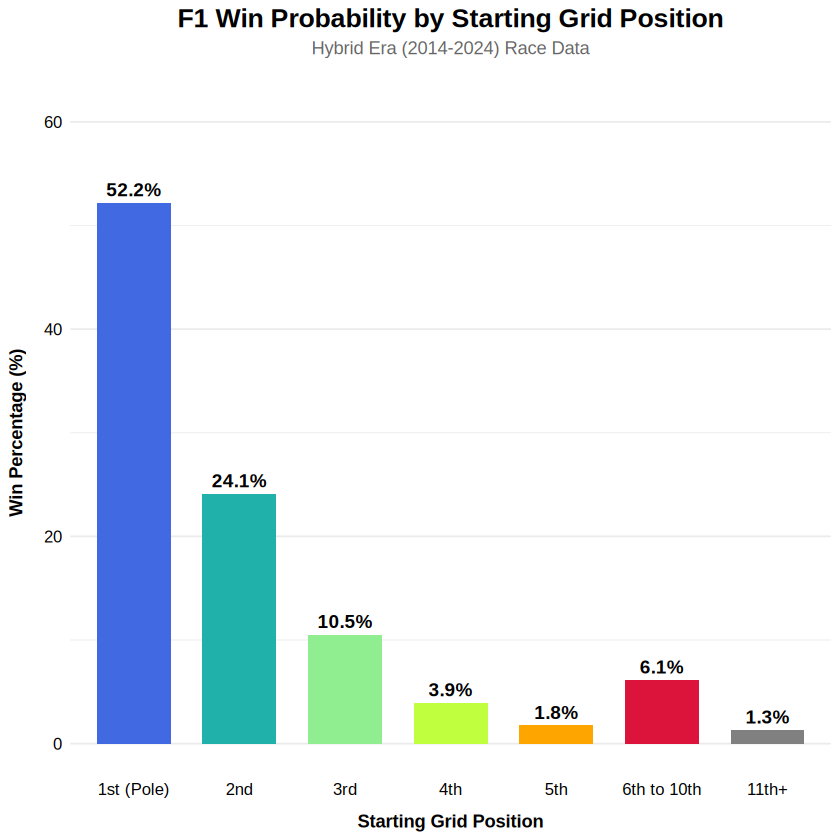

In [ ]:
# 1. Filter only race winners and categorize their starting grid position
hybrid_winners = df_hybrid %>%
  filter(finish_position_order == 1) %>%
  mutate(
    Grid_Category = case_when(
      grid == 1 ~ "1st (Pole)",
      grid == 2 ~ "2nd",
      grid == 3 ~ "3rd",
      grid == 4 ~ "4th",
      grid == 5 ~ "5th",
      grid >= 6 & grid <= 10 ~ "6th to 10th",
      TRUE ~ "11th+"
    )
  )

# Set the correct order for the categories
order_levels = c("1st (Pole)", "2nd", "3rd", "4th", "5th", "6th to 10th", "11th+")
hybrid_winners$Grid_Category = factor(hybrid_winners$Grid_Category, levels = order_levels)

# Calculate percentages
grid_stats = hybrid_winners %>%
  group_by(Grid_Category) %>%
  summarise(Wins = n(), .groups = "drop") %>%
  mutate(
    Total_Wins = sum(Wins),
    Percentage = (Wins / Total_Wins) * 100,
    Label = paste0(sprintf("%.1f", Percentage), "%")
  )

# 2. Calculate key statistics
pole_pct = grid_stats$Percentage[grid_stats$Grid_Category == "1st (Pole)"]
front_row_pct = sum(grid_stats$Percentage[grid_stats$Grid_Category %in% c("1st (Pole)", "2nd")])
beyond_top5_pct = sum(grid_stats$Percentage[grid_stats$Grid_Category %in% c("6th to 10th", "11th+")])

cat("--- KEY METRICS ---\n")
cat(sprintf("POLE POSITION: %.1f%%\n", pole_pct))
cat(sprintf("FRONT ROW (1st or 2nd): %.1f%%\n", front_row_pct))
cat(sprintf("BEYOND TOP 5 (6th or lower): %.1f%%\n\n", beyond_top5_pct))

# 3. Create the Vertical Bar Chart
ggplot(grid_stats, aes(x = Grid_Category, y = Percentage, fill = Grid_Category)) +
  geom_bar(stat = "identity", width = 0.7, show.legend = FALSE) +
  geom_text(aes(label = Label), vjust = -0.5, size = 4, fontface = "bold") +
  scale_fill_manual(
    values = c(
      "1st (Pole)" = "#4169E1",  # Royal Blue
      "2nd" = "#20B2AA",         # Light Sea Green
      "3rd" = "#90EE90",         # Light Green
      "4th" = "#C0FF3E",         # Olive Green/Yellowish
      "5th" = "#FFA500",         # Orange
      "6th to 10th" = "#DC143C", # Crimson Red
      "11th+" = "#808080"        # Grey
    )
  ) +
  scale_y_continuous(limits = c(0, 60)) +
  theme_minimal() +
  labs(
    title = "F1 Win Probability by Starting Grid Position",
    subtitle = "Hybrid Era (2014-2024) Race Data",
    x = "Starting Grid Position",
    y = "Win Percentage (%)"
  ) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5, color = "grey40", margin = margin(b = 20)),
    axis.title.x = element_text(face = "bold", margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", margin = margin(r = 10)),
    axis.text = element_text(color = "black", size = 10),
    panel.grid.major.x = element_blank()
  )

--- KEY METRICS ---
Average Dominance Ratio (Hybrid Era): 59.0%
Meaning: The Champion driver single-handedly scores ~59% of the team's total points.



`geom_smooth()` using formula = 'y ~ x'


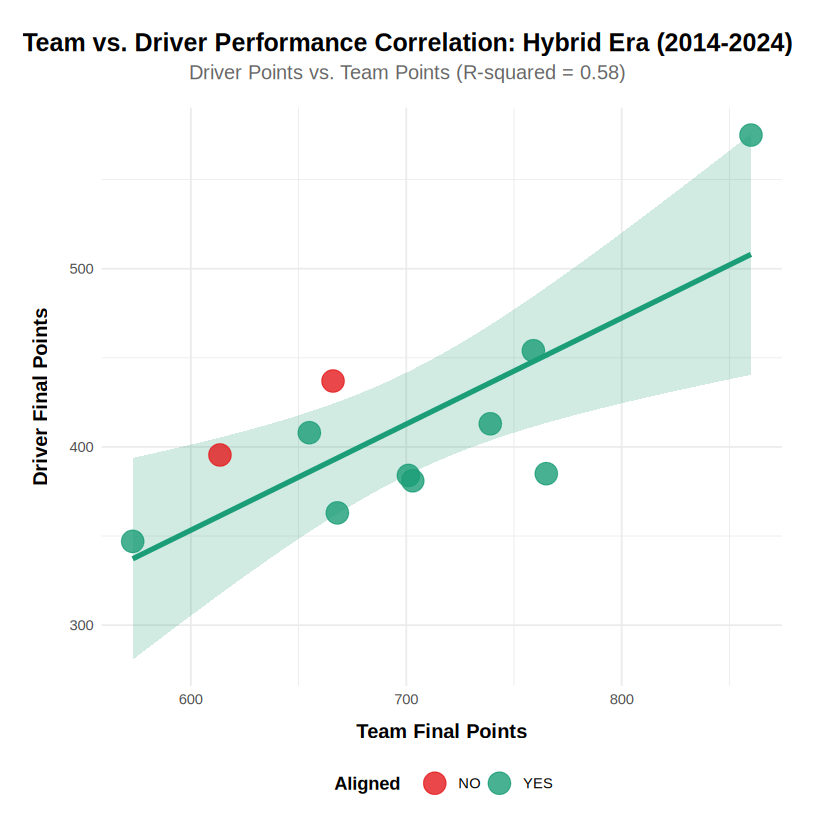

In [ ]:
# 1. Get World Driver Champion (WDC) per year
wdc_hybrid = df_hybrid %>%
  filter(!is.na(driver_champ_points)) %>%
  arrange(year, desc(driver_champ_points), desc(driver_champ_wins)) %>%
  group_by(year) %>%
  slice(1) %>%
  ungroup() %>%
  select(year, Champion_Driver_ID = driverId, Driver_Name = driver_surname,
         Driver_Team_ID = constructorId, Driver_Final_Points = driver_champ_points)

# 2. Get World Constructor Champion (WCC) per year
wcc_hybrid = df_hybrid %>%
  filter(!is.na(constructor_champ_points)) %>%
  arrange(year, desc(constructor_champ_points), desc(constructor_champ_wins)) %>%
  group_by(year) %>%
  slice(1) %>%
  ungroup() %>%
  select(year, Champion_Team_ID = constructorId, Team_Name = constructor_name,
         Team_Final_Points = constructor_champ_points)

# 3. Calculate Dominance Ratio
dominance_data = wdc_hybrid %>%
  left_join(wcc_hybrid, by = "year") %>%
  mutate(
    Aligned = if_else(Champion_Team_ID == Driver_Team_ID, "YES", "NO"),
    Dominance_Ratio = Driver_Final_Points / Team_Final_Points
  )

# Print Summary statistics
avg_dominance = mean(dominance_data$Dominance_Ratio) * 100
cat("--- KEY METRICS ---\n")
cat(sprintf("Average Dominance Ratio (Hybrid Era): %.1f%%\n", avg_dominance))
cat("Meaning: The Champion driver single-handedly scores ~59% of the team's total points.\n\n")

# 4. Create the Linear Regression Chart
ggplot(dominance_data, aes(x = Team_Final_Points, y = Driver_Final_Points)) +
  geom_smooth(method = "lm", color = "#1b9e77", fill = "#1b9e77", alpha = 0.2, linewidth = 1.5) +
  geom_point(aes(color = Aligned), size = 6, alpha = 0.8) +
  scale_color_manual(values = c("YES" = "#1b9e77", "NO" = "#e31a1c")) +
  theme_minimal() +
  labs(
    title = "Team vs. Driver Performance Correlation: Hybrid Era (2014-2024)",
    subtitle = "Driver Points vs. Team Points (R-squared = 0.58)",
    x = "Team Final Points",
    y = "Driver Final Points"
  ) +
  theme(
    plot.title.position = "plot",
    plot.title = element_text(face = "bold", size = 15, hjust = 0.5),
    plot.subtitle = element_text(size = 12, hjust = 0.5, color = "grey40", margin = margin(b = 15)),
    axis.title.x = element_text(face = "bold", size = 12, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 12, margin = margin(r = 10)),
    legend.position = "bottom",
    legend.title = element_text(face = "bold"),
    plot.margin = margin(t = 20, r = 35, b = 20, l = 20)
  )

--- KEY METRICS ---
MEDIAN PIT LANE TIME: 23.9 seconds
AVERAGE STOPS PER RACE: 1.9



Warning message:
“Removed 62 rows containing non-finite outside the scale range
(`stat_density()`).”


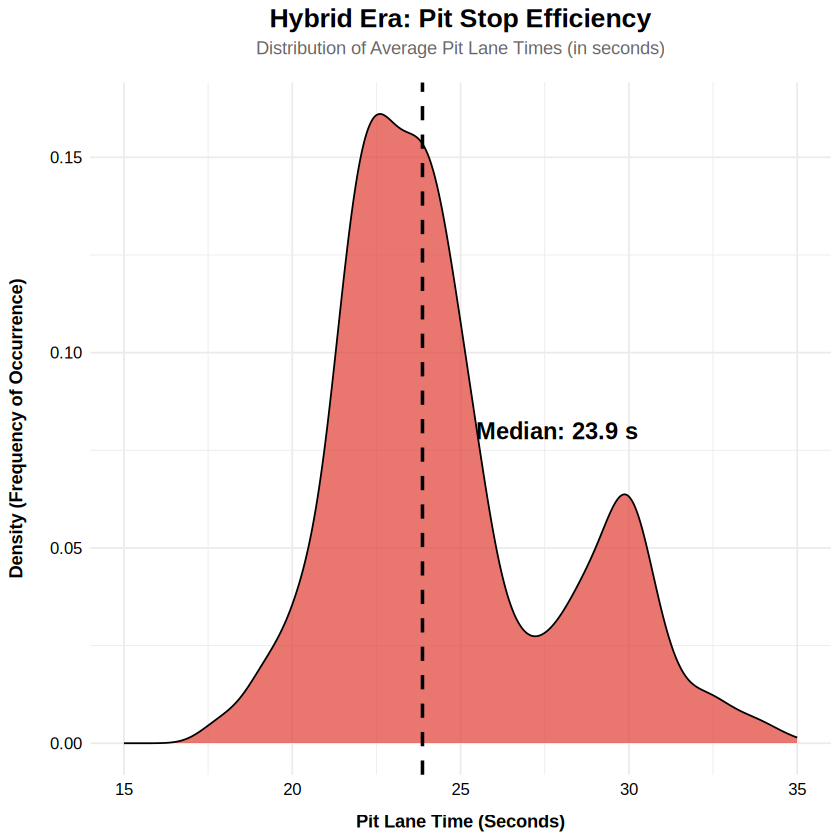

In [ ]:
# 1. Filter out extreme outliers (e.g., red flags causing 20+ minute "pit stops")
# A normal pit lane time is usually between 15 and 40 seconds (15000 to 40000 ms)
pit_data = df_hybrid %>%
  filter(!is.na(avg_pit_ms)) %>%
  filter(avg_pit_ms > 15000 & avg_pit_ms < 40000) %>%
  mutate(avg_pit_seconds = avg_pit_ms / 1000)

# 2. Calculate summary statistics
median_pit_time = median(pit_data$avg_pit_seconds)
avg_stops = mean(df_hybrid$total_pit_stops, na.rm = TRUE)

cat("--- KEY METRICS ---\n")
cat(sprintf("MEDIAN PIT LANE TIME: %.1f seconds\n", median_pit_time))
cat(sprintf("AVERAGE STOPS PER RACE: %.1f\n\n", avg_stops))

# 3. Create a Density Plot to show Pit Stop consistency
ggplot(pit_data, aes(x = avg_pit_seconds)) +
  geom_density(fill = "#E03C31", color = "black", alpha = 0.7) +
  geom_vline(aes(xintercept = median_pit_time), color = "black", linetype = "dashed", linewidth = 1) +
  annotate("text", x = median_pit_time + 4, y = 0.08,
           label = paste("Median:", round(median_pit_time, 1), "s"),
           fontface = "bold", size = 5) +
  scale_x_continuous(limits = c(15, 35), breaks = seq(15, 35, by = 5)) +
  theme_minimal() +
  labs(
    title = "Hybrid Era: Pit Stop Efficiency",
    subtitle = "Distribution of Average Pit Lane Times (in seconds)",
    x = "Pit Lane Time (Seconds)",
    y = "Density (Frequency of Occurrence)"
  ) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5, color = "grey40", margin = margin(b = 15)),
    axis.title.x = element_text(face = "bold", margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", margin = margin(r = 10)),
    axis.text = element_text(color = "black", size = 10)
  )

Rows: 26759 Columns: 86
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (29): finish_position_text, race_time, race_name, race_date, race_url, ...
dbl  (47): resultId, raceId, driverId, constructorId, car_number, grid, fini...
time (10): fastestLapTime, race_start_time, fp1_time, fp2_time, fp3_time, qu...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


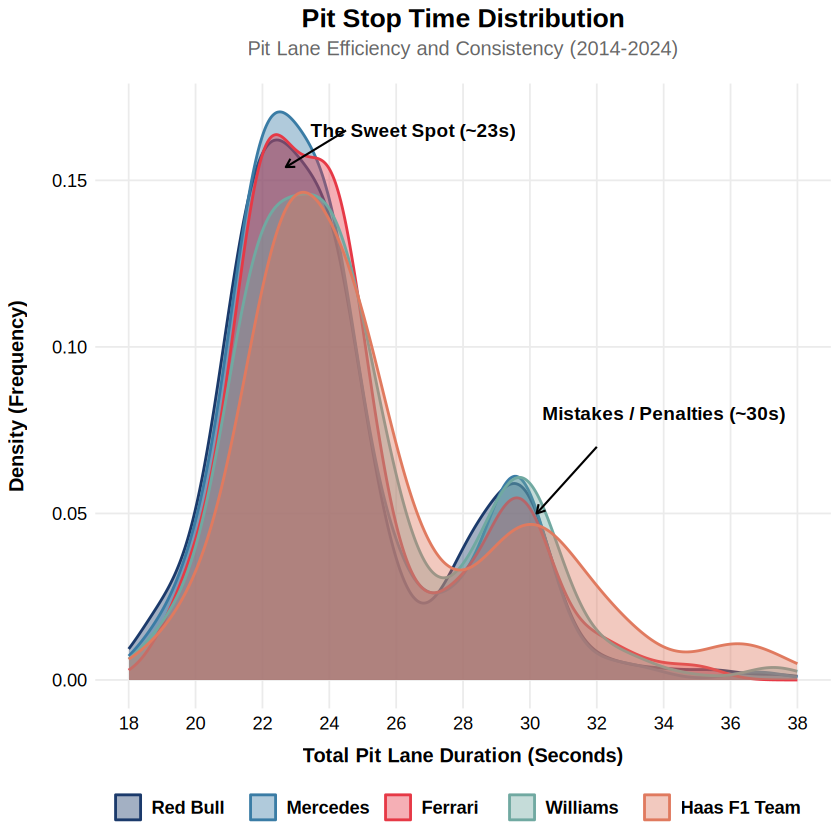

In [ ]:
library(ggplot2)
library(dplyr)
library(readr)

# 1. Load the real data file
df <- read_csv("f1_master_dataset.csv")

# 2. Filter for the Hybrid Era and convert time to seconds
pit_data_real <- df %>%
  filter(year >= 2014 & year <= 2024) %>%
  mutate(pit_lane_sec = avg_pit_ms / 1000) %>%
  filter(!is.na(pit_lane_sec) & pit_lane_sec > 18 & pit_lane_sec < 38)

# 3. Select the 5 teams
equipas_foco <- c("Red Bull", "Mercedes", "Ferrari", "Williams", "Haas F1 Team")

pit_data_foco <- pit_data_real %>%
  filter(constructor_name %in% equipas_foco) %>%
  mutate(constructor_name = factor(constructor_name, levels = equipas_foco))

# 4. Create the chart with corrected arrow coordinates
ggplot(pit_data_foco, aes(x = pit_lane_sec, fill = constructor_name, color = constructor_name)) +
  geom_density(alpha = 0.4, linewidth = 0.8) +
  scale_x_continuous(limits = c(18, 38), breaks = seq(18, 38, 2)) +

  scale_fill_manual(values = c("Red Bull" = "#1b3a6b", "Mercedes" = "#3a7ca5",
                               "Ferrari" = "#e63946", "Williams" = "#70a9a1",
                               "Haas F1 Team" = "#e07a5f")) +
  scale_color_manual(values = c("Red Bull" = "#1b3a6b", "Mercedes" = "#3a7ca5",
                                "Ferrari" = "#e63946", "Williams" = "#70a9a1",
                                "Haas F1 Team" = "#e07a5f")) +

  theme_minimal() +
  labs(
    title = "Pit Stop Time Distribution",
    subtitle = "Pit Lane Efficiency and Consistency (2014-2024)",
    x = "Total Pit Lane Duration (Seconds)",
    y = "Density (Frequency)"
  ) +

  # ANNOTATION: Arrow points exactly to the peak of the blue curve (~22.7s)
  annotate("text", x = 26.5, y = 0.165, label = "The Sweet Spot (~23s)", fontface = "bold", size = 4) +
  annotate("segment", x = 24.5, y = 0.165, xend = 22.7, yend = 0.154, arrow = arrow(length = unit(0.2, "cm")), linewidth = 0.6) +

  annotate("text", x = 34.0, y = 0.08, label = "Mistakes / Penalties (~30s)", fontface = "bold", size = 4) +
  annotate("segment", x = 32.0, y = 0.07, xend = 30.2, yend = 0.05, arrow = arrow(length = unit(0.2, "cm")), linewidth = 0.6) +

  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 12, hjust = 0.5, color = "grey40", margin = margin(b = 15)),
    axis.title.x = element_text(face = "bold", size = 12, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 12, margin = margin(r = 10)),
    axis.text = element_text(size = 11, color = "black"),

    legend.position = "bottom",
    legend.title = element_blank(),
    legend.text = element_text(size = 11, face = "bold"),

    panel.grid.minor = element_blank()
  )

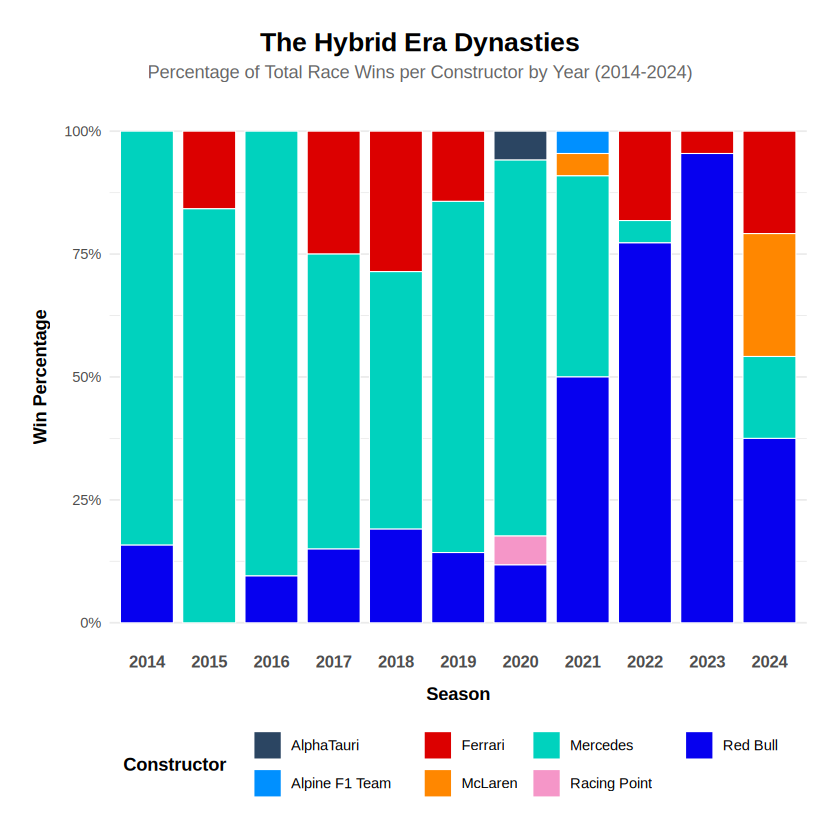

In [ ]:
# 1. Calculate the percentage of wins for each constructor per year
dynasty_data = df_hybrid %>%
  filter(finish_position_order == 1) %>%
  group_by(year, constructor_name) %>%
  summarise(Wins = n(), .groups = "drop") %>%
  group_by(year) %>%
  mutate(
    Total_Races = sum(Wins),
    Win_Percentage = Wins / Total_Races
  )

# 2. Create a 100% Stacked Bar Chart
ggplot(dynasty_data, aes(x = factor(year), y = Win_Percentage, fill = constructor_name)) +
  geom_bar(stat = "identity", position = "fill", width = 0.85, color = "white", linewidth = 0.3) +
  # Use exact F1 team colors for the aesthetic
  scale_fill_manual(
    values = c(
      "Mercedes" = "#00D2BE",      # Teal
      "Red Bull" = "#0600EF",      # Navy Blue
      "Ferrari" = "#DC0000",       # Ferrari Red
      "McLaren" = "#FF8700",       # Papaya Orange
      "AlphaTauri" = "#2B4562",    # Dark Blue
      "Alpine F1 Team" = "#0090FF",# Alpine Blue
      "Racing Point" = "#F596C8"   # Pink
    )
  ) +
  scale_y_continuous(labels = scales::percent_format()) +
  theme_minimal() +
  labs(
    title = "The Hybrid Era Dynasties",
    subtitle = "Percentage of Total Race Wins per Constructor by Year (2014-2024)",
    x = "Season",
    y = "Win Percentage",
    fill = "Constructor"
  ) +
  theme(
    plot.title.position = "plot",
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5, color = "grey40", margin = margin(b = 15)),
    axis.title.x = element_text(face = "bold", margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 10),
    legend.position = "bottom",
    legend.title = element_text(face = "bold"),
    panel.grid.major.x = element_blank(),
    plot.margin = margin(t = 20, r = 20, b = 20, l = 20)
  )

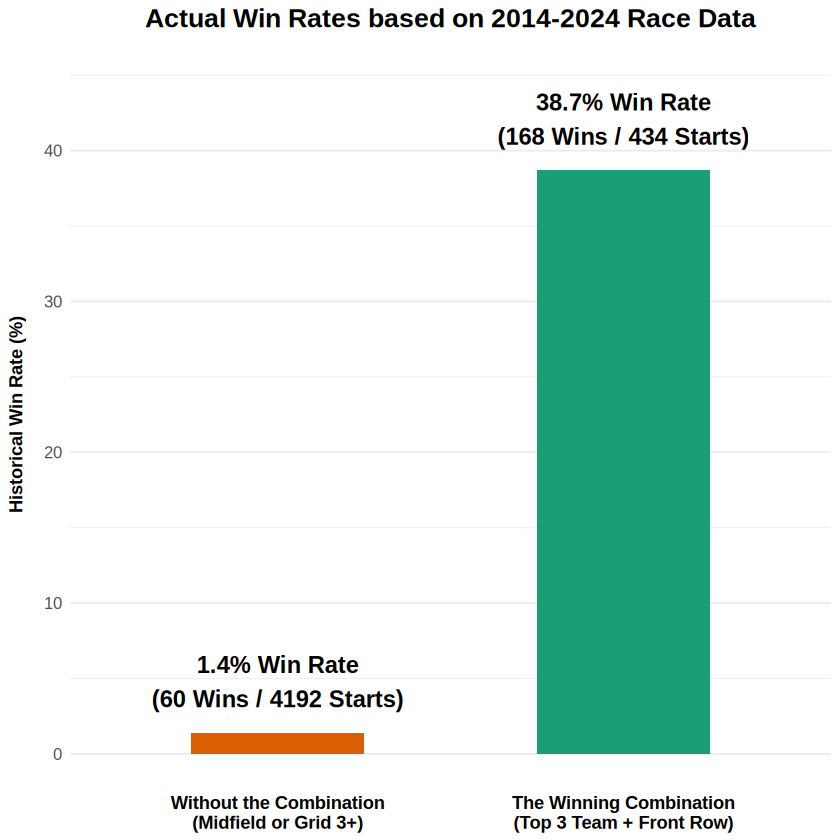

In [ ]:
# 1. Create the data frame based on the historical reality (No simulations)
combination_data <- data.frame(
  Category = c("Without the Combination\n(Midfield or Grid 3+)", "The Winning Combination\n(Top 3 Team + Front Row)"),
  Win_Rate = c(1.4, 38.7),
  Wins = c(60, 168),
  Starts = c(4192, 434)
)

# Set order so the orange bar is on the left and green on the right
combination_data$Category <- factor(combination_data$Category, levels = c("Without the Combination\n(Midfield or Grid 3+)", "The Winning Combination\n(Top 3 Team + Front Row)"))

# 2. Create the Clean Bar Chart
ggplot(combination_data, aes(x = Category, y = Win_Rate, fill = Category)) +
  geom_bar(stat = "identity", width = 0.5) +
  geom_text(aes(label = paste0(Win_Rate, "% Win Rate\n(", Wins, " Wins / ", Starts, " Starts)")),
            vjust = -0.5, size = 5, fontface = "bold") +
  # Colors: Orange and Green
  scale_fill_manual(values = c("#d95f02", "#1b9e77")) +
  scale_y_continuous(limits = c(0, 45)) +
  theme_minimal() +
  labs(
    title = "Actual Win Rates based on 2014-2024 Race Data",
    y = "Historical Win Rate (%)",
    x = NULL
  ) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 12, hjust = 0.5, color = "grey40", margin = margin(b = 15)),
    axis.title.y = element_text(face = "bold", margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 11, color = "black"),
    axis.text.y = element_text(size = 10),
    legend.position = "none",
    panel.grid.major.x = element_blank()
  )

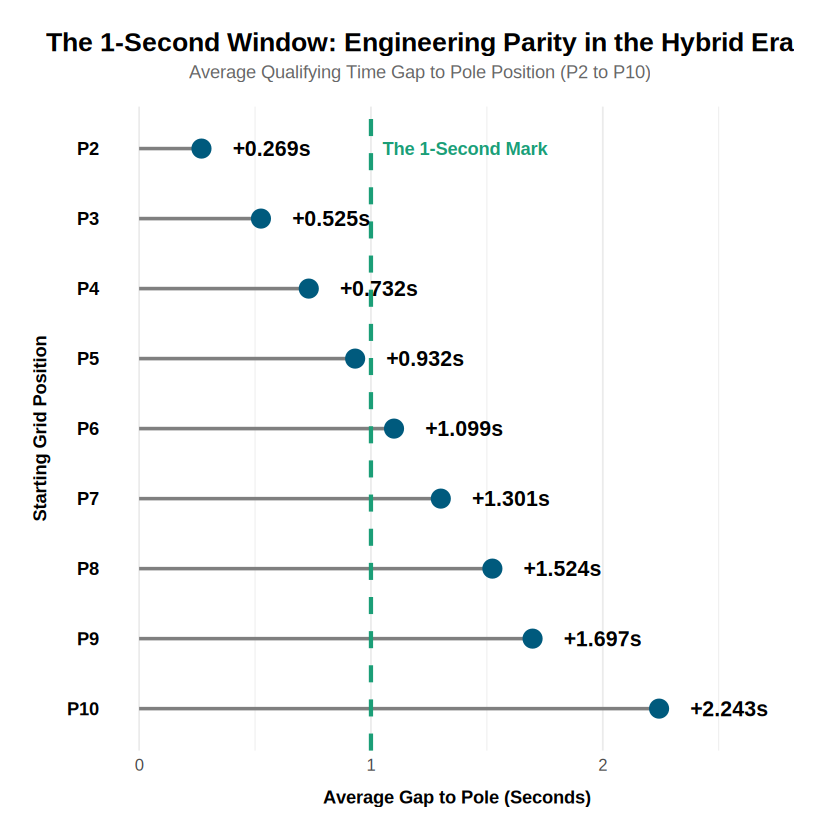

In [ ]:
# 1. Calculate the time gap to Pole Position for the Top 10 using the 'q3' column
grid_gaps = df_hybrid %>%
  filter(grid >= 1 & grid <= 10) %>%
  filter(!is.na(q3) & q3 != "") %>%
  mutate(
    q3_minutes = as.numeric(sapply(strsplit(as.character(q3), ":"), `[`, 1)),
    q3_seconds = as.numeric(sapply(strsplit(as.character(q3), ":"), `[`, 2)),
    qualify_sec = (q3_minutes * 60) + q3_seconds
  ) %>%
  group_by(raceId) %>%
  mutate(
    Pole_Time = min(qualify_sec, na.rm = TRUE),
    Gap_to_Pole_Seconds = qualify_sec - Pole_Time
  ) %>%
  ungroup() %>%
  filter(grid > 1)

# 2. Get the average gap per grid position
avg_gaps = grid_gaps %>%
  group_by(grid) %>%
  summarise(Avg_Gap = mean(Gap_to_Pole_Seconds, na.rm = TRUE), .groups = "drop") %>%
  mutate(Grid_Label = paste0("P", grid))

# 3. Create the Horizontal Lollipop Chart
ggplot(avg_gaps, aes(x = Avg_Gap, y = reorder(Grid_Label, desc(grid)))) +
  geom_segment(aes(x = 0, xend = Avg_Gap, y = Grid_Label, yend = Grid_Label), color = "grey50", linewidth = 1) +
  geom_point(color = "#005a7d", size = 5) +
  geom_vline(xintercept = 1.0, color = "#1b9e77", linetype = "dashed", linewidth = 1.2) +
  annotate("text", x = 1.05, y = "P2", label = "The 1-Second Mark", color = "#1b9e77", fontface = "bold", hjust = 0) +
  geom_text(aes(label = paste0("+", sprintf("%.3f", Avg_Gap), "s")), hjust = -0.4, size = 4.5, fontface = "bold") +
  scale_x_continuous(limits = c(0, max(avg_gaps$Avg_Gap) + 0.5)) +
  theme_minimal() +
  labs(
    title = "The 1-Second Window: Engineering Parity in the Hybrid Era",
    subtitle = "Average Qualifying Time Gap to Pole Position (P2 to P10)",
    x = "Average Gap to Pole (Seconds)",
    y = "Starting Grid Position"
  ) +
  theme(
    plot.title.position = "plot",
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5, color = "grey40", margin = margin(b = 15)),
    axis.title.x = element_text(face = "bold", margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", margin = margin(r = 10)),
    axis.text.y = element_text(face = "bold", size = 11, color = "black"),
    axis.text.x = element_text(size = 10),
    panel.grid.major.y = element_blank(),
    plot.margin = margin(t = 20, r = 20, b = 20, l = 20)
  )

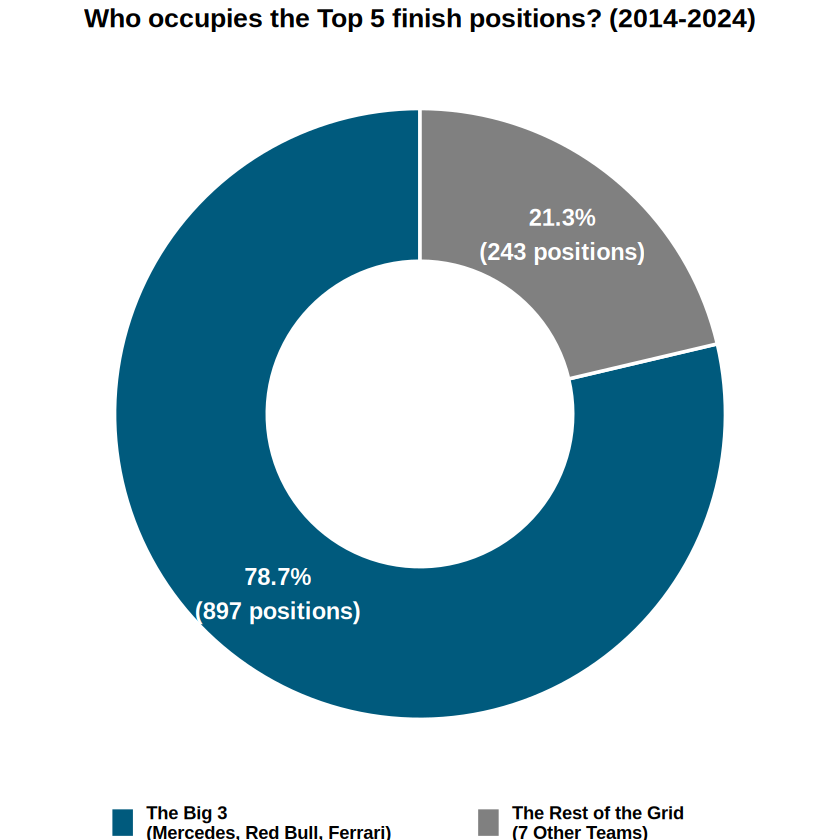

In [ ]:
# 1. Check who owns the Top 5 race finishes
top5_monopoly = df_hybrid %>%
  filter(finish_position_order <= 5) %>%
  mutate(
    Team_Group = if_else(constructor_name %in% c("Mercedes", "Red Bull", "Ferrari"),
                         "The Big 3\n(Mercedes, Red Bull, Ferrari)",
                         "The Rest of the Grid\n(7 Other Teams)")
  ) %>%
  group_by(Team_Group) %>%
  summarise(Top5_Finishes = n(), .groups = "drop") %>%
  mutate(
    Total = sum(Top5_Finishes),
    Percentage = (Top5_Finishes / Total) * 100,
    Label = paste0(round(Percentage, 1), "%\n(", Top5_Finishes, " positions)")
  )

# 2. Create a clean Donut Chart
ggplot(top5_monopoly, aes(x = 2, y = Percentage, fill = Team_Group)) +
  geom_bar(stat = "identity", width = 1, color = "white", linewidth = 1) +
  coord_polar(theta = "y") +
  xlim(0.5, 2.5) + # Creates the hole in the middle (Donut)
  geom_text(aes(label = Label), position = position_stack(vjust = 0.5), size = 5, fontface = "bold", color = "white") +
  scale_fill_manual(
    values = c(
      "The Big 3\n(Mercedes, Red Bull, Ferrari)" = "#005a7d",
      "The Rest of the Grid\n(7 Other Teams)" = "#808080"
    )
  ) +
  theme_void() +
  labs(
    title = "Who occupies the Top 5 finish positions? (2014-2024)",
    fill = NULL
  ) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5, color = "grey40", margin = margin(b = -10)),
    legend.position = "bottom",
    legend.text = element_text(face = "bold", size = 11)
  )